# Kisállat-szegmentálás U-Nettel az Oxford-IIIT Pet adathalmazon

**Tárgy:** Neurális hálók — féléves projekt
**Szerző:** Varga Veronika
**Keretrendszer:** PyTorch

## Összefoglaló

A feladat **szemantikus szegmentálás**: a háló egy kisállatról (macska vagy kutya)
készült fotó *minden egyes pixeléhez* megmondja, hogy az a **kisállathoz**, a
**háttérhez** vagy a kettő közötti **határsávhoz** tartozik. Ez nehezebb, mint a
képosztályozás, mert nem egyetlen címkét, hanem egy, a képpel azonos méretű
címketérképet kell előállítani.

- **Adathalmaz:** [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) —
  37 macska- és kutyafajta, kb. 7400 kép, pixelszintű ún. *trimap* maszkokkal.
- **Modell:** nulláról épített **U-Net** (encoder–decoder skip kapcsolatokkal), kb. 7,8 millió
  paraméter, előtanított súlyok nélkül.
- **Tanítás:** CrossEntropy + Dice loss, Adam, a validációs mIoU-hoz kötött tanulásiráta-ütemezés,
  TensorBoard-naplózás.
- **Eredmény:** a hivatalos teszt spliten (3669 kép) a **mIoU 0,737**, szemben a „mindig
  hátteret jósoló” alapmodell 0,193-as értékével (a pontos számok a 6. fejezet kimenetében).

A notebook a projekt `unet_pet` csomagjának függvényeit hívja lépésről lépésre; a
csomag kódja a repóban, tesztekkel együtt található. Alapértelmezésben **nem tanít**
(`TRAIN = False`): betölti a mentett súlyokat (`models/unet_pet_best.pt`), és csak
kiértékel, illetve ábrákat készít. Így CPU-n is néhány perc alatt végigfut.

### Tartalom

0. Összefoglaló (fent)
1. Beállítások
2. Az adathalmaz
3. Előfeldolgozás és augmentáció
4. A modell: U-Net
5. Tanítás
6. Kiértékelés a teszt spliten
7. Vizuális eredmények és hibaelemzés
8. Kísérletek összevetése: CE + Dice vs. csak CE
9. Összegzés és korlátok
10. Reprodukálás

## 1. Beállítások

Az első kódcella importálja a szükséges csomagokat és a projekt moduljait, majd
beállítja a notebook **kapcsolóit**:

| Kapcsoló | Alapérték | Jelentés |
|----------|-----------|----------|
| `TRAIN` | `False` | `True` esetén a háló újratanul (CPU-n kb. 2 óra, GPU-n néhány perc); `False` esetén a mentett súlyokat tölti be |
| `RUN_TEST_EVAL` | `True` | élő kiértékelés a teljes teszt spliten (CPU-n kb. 4 perc); `False` esetén a mentett `results/test_metrics.json` eredményt mutatja |
| `EVAL_LIMIT` | `None` | ha egy szám, csak az első ennyi tesztképen értékel (gyors próbához) |

**Reprodukálhatóság.** Minden véletlenszám-generátort (Python `random`, NumPy, PyTorch,
a DataLoader keverése és a train/val felosztás) ugyanabból a seedből (`42`) indítunk a
`set_seed` függvénnyel, a notebook legelején. Minden hiperparaméter egyetlen
konfigurációs fájlban van (`configs/default.yaml`), amit a `load_config` egy típusos
dataclass-ba tölt; a kód sehol nem tartalmaz beégetett hiperparamétert.

Az eszköz automatikusan választódik: CUDA-s GPU → Apple MPS → CPU.

In [1]:
import json
import platform
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import Markdown, display

from unet_pet.config import load_config
from unet_pet.data import (
    CLASS_NAMES,
    PetSegmentationDataset,
    build_transform,
    class_pixel_fractions,
    load_base_datasets,
    load_sample_data,
    make_datasets,
    trimap_to_labels,
)
from unet_pet.evaluate import (
    examples_figure,
    load_trained_model,
    make_eval_dataset,
    metrics_path,
    run_evaluation,
)
from unet_pet.metrics import per_image_iou
from unet_pet.model import build_model, count_parameters
from unet_pet.train import fit
from unet_pet.utils import get_device, project_root, set_seed
from unet_pet.visualize import (
    CLASS_COLORS,
    plot_confusion_matrix,
    plot_history,
    show_predictions,
)

warnings.filterwarnings("ignore", category=UserWarning)
%matplotlib inline

# ---- notebook switches -------------------------------------------------------------
TRAIN = False  # True: retrain the network (CPU: ~2 h, GPU: a few minutes)
RUN_TEST_EVAL = True  # True: live evaluation on the whole test split (CPU: ~4 min)
EVAL_LIMIT = None  # e.g. 200: evaluate only the first N test images (quick check)
# -------------------------------------------------------------------------------------

ROOT = project_root()
cfg = load_config("configs/default.yaml")
set_seed(cfg.seed)
device = get_device()


def rel(path):
    # Path relative to the repository root, for printing (no absolute paths in outputs).
    try:
        return path.resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return str(path)


print(
    f"Python {platform.python_version()} | torch {torch.__version__} | "
    f"torchvision {torchvision.__version__}"
)
print(f"device: {device} | seed: {cfg.seed}")

Python 3.11.9 | torch 2.15.0+cpu | torchvision 0.29.2+cpu
device: cpu | seed: 42


A betöltött konfiguráció (az útvonalak a repó gyökeréhez képest értendők):

In [2]:
for section, values in cfg.to_dict().items():
    if isinstance(values, dict):
        if section in ("paths", "data"):  # Path fields: print relative to the repo root
            obj = getattr(cfg, section)
            values = {
                k: rel(v) if isinstance(v := getattr(obj, k), Path) else values[k] for k in values
            }
        print(f"{section}:")
        for key, value in values.items():
            print(f"    {key:<20} {value}")
    else:
        print(f"{section}: {values}")

seed: 42
data:
    root                 data
    img_size             128
    val_fraction         0.15
    num_workers          0
    mean                 [0.485, 0.456, 0.406]
    std                  [0.229, 0.224, 0.225]
    hflip_prob           0.5
    color_jitter         [0.2, 0.2, 0.2, 0.0]
model:
    in_channels          3
    num_classes          3
    base_channels        32
    depth                4
    bilinear             False
train:
    epochs               25
    batch_size           16
    lr                   0.001
    weight_decay         0.0001
    scheduler            reduce_on_plateau
    scheduler_factor     0.5
    scheduler_patience   3
    dice_weight          1.0
    log_images_every     1
    num_log_images       4
    amp                  True
paths:
    runs                 runs
    checkpoints          checkpoints
    best_weights         models/unet_pet_best.pt
    history              models/unet_pet_history.json
    results              results


## 2. Az adathalmaz

Az **Oxford-IIIT Pet** adathalmazt az Oxfordi Egyetem Visual Geometry Group-ja tette közzé
(Parkhi et al., *Cats and Dogs*, CVPR 2012):
<https://www.robots.ox.ac.uk/~vgg/data/pets/>.
37 fajtát tartalmaz (12 macska- és 25 kutyafajta), fajtánként kb. 200 fotóval. A képek
mérete és oldalaránya változó; a fotókon az állat különböző pózokban, sokféle háttér előtt
látható.

A szegmentációs címke egy ún. **trimap**: minden pixel értéke 1 = kisállat, 2 = háttér,
3 = határ (a körvonal menti bizonytalan sáv). A projektben ezt `mask - 1` művelettel a
0-tól induló **osztálycímkékre** képezzük le, ahogy a PyTorch `CrossEntropyLoss` várja:

| Címke | Osztály | Szín az ábrákon |
|-------|---------|-----------------|
| 0 | kisállat (`pet`) | narancs |
| 1 | háttér (`background`) | sötétszürke |
| 2 | határ (`border`) | sárga |

**Letöltés.** A `torchvision.datasets.OxfordIIITPet` osztály első használatkor automatikusan
letölti az adathalmazt (kb. 800 MB) a `data/` mappába. Ha ez nem sikerül (például nincs
internet), a notebook ezt jelzi, és a további lépéseket a repóban mellékelt
`sample_data/` mappa 8 képén (4 macska, 4 kutya, a teszt splitből) mutatja be.

**Splitek és adatszivárgás.** A hivatalos `trainval` splitet seedelt véletlen felosztással
bontjuk **tanító** (85%) és **validációs** (15%) részre. A modellválasztás (a legjobb epoch)
és a tanulási ráta ütemezése kizárólag a validációs eredményen alapul; a hivatalos
`test` splitet csak a legvégső kiértékelésnél használjuk, így a teszteredmény
torzítatlan becslés.

In [3]:
try:
    trainval_base, test_base = load_base_datasets(cfg, download=True)
    DATA_AVAILABLE = True
except Exception as exc:  # no internet / download failed
    DATA_AVAILABLE = False
    print(f"FIGYELEM: az Oxford-IIIT Pet adathalmaz nem érhető el ({type(exc).__name__}: {exc}).")
    print(
        "A notebook a sample_data/ mappa 8 képével folytatódik; a teszt-kiértékelésnél "
        "a mentett eredmények (results/test_metrics.json) jelennek meg."
    )

if DATA_AVAILABLE:
    datasets = make_datasets(cfg, trainval_base, test_base)
    rows = [
        ("train (trainval 85%)", len(datasets["train"])),
        ("validation (trainval 15%)", len(datasets["val"])),
        ("test (hivatalos)", len(datasets["test"])),
    ]
    display(
        Markdown(
            "| split | képek száma |\n|---|---|\n"
            + "\n".join(f"| {name} | {n} |" for name, n in rows)
        )
    )
    sizes = [trainval_base[i][0].size for i in range(5)]
    print(
        "Az első 5 eredeti kép mérete (szélesség x magasság):",
        ", ".join(f"{w}x{h}" for w, h in sizes),
    )

| split | képek száma |
|---|---|
| train (trainval 85%) | 3128 |
| validation (trainval 15%) | 552 |
| test (hivatalos) | 3669 |

Az első 5 eredeti kép mérete (szélesség x magasság): 394x500, 450x313, 500x465, 500x351, 600x363


Néhány példa a címkékkel együtt (bal oldalt a kép, középen a maszk, jobb oldalt a maszk a
képre vetítve). A határsáv (sárga) a kisállat körvonalát követi, és jellemzően csak néhány
pixel széles.

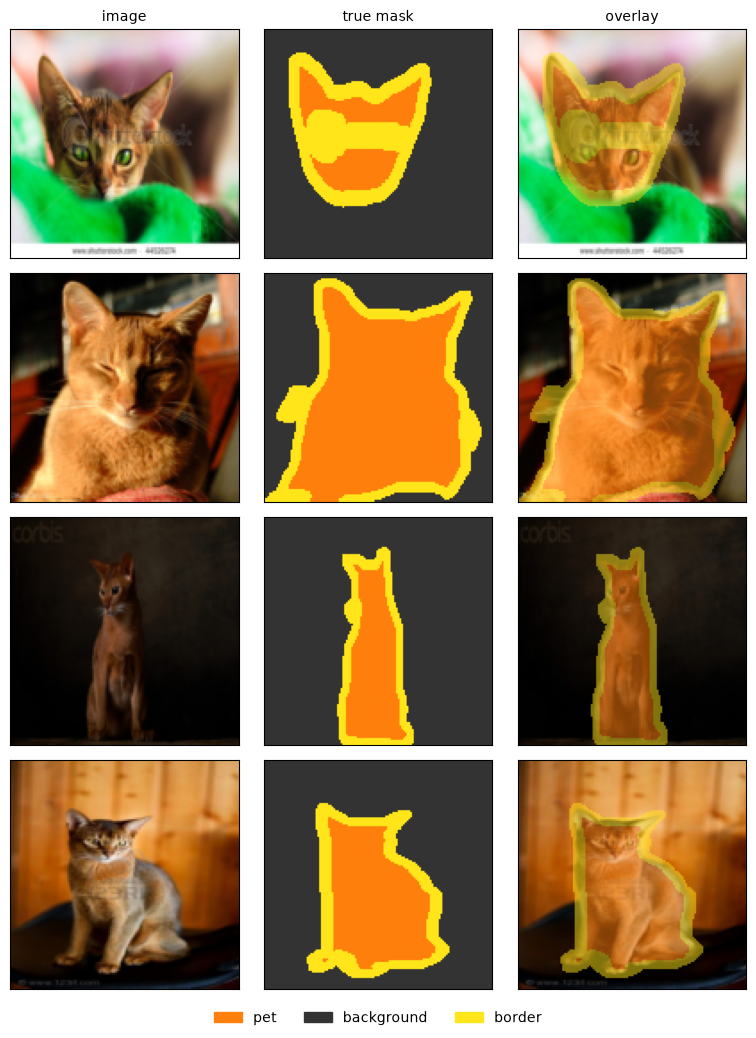

In [4]:
if DATA_AVAILABLE:
    preview = [datasets["val"][i] for i in range(4)]
    images = torch.stack([img for img, _ in preview])
    masks = torch.stack([m for _, m in preview])
    titles = None
else:
    images, masks, names = load_sample_data(cfg)
    images, masks, titles = images[:4], masks[:4], names[:4]

show_predictions(images, masks, mean=cfg.data.mean, std=cfg.data.std, n=4, titles=titles)
plt.show()

### Osztályeloszlás

Megnézzük, a pixelek mekkora hányada esik az egyes osztályokba (a tanító split első 500
képe alapján, átméretezés után). Ez a loss és a metrika választásánál fontos: ha egy
osztály nagyon ritka, a pixelenként egyforma súlyú loss és a pixelpontosság hajlamos
figyelmen kívül hagyni.

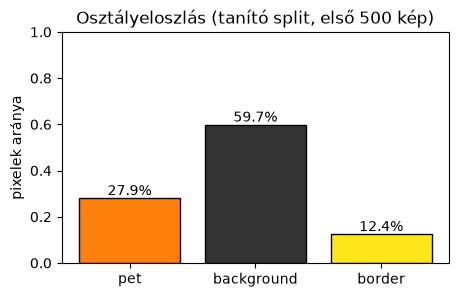

In [5]:
if DATA_AVAILABLE:
    eval_tf = build_transform(cfg, train=False)
    train_plain = PetSegmentationDataset(trainval_base, eval_tf, datasets["train"].indices)
    fractions = class_pixel_fractions(train_plain, max_items=500)
    source = "tanító split, első 500 kép"
else:
    _, sample_masks, _ = load_sample_data(cfg)
    counts = torch.bincount(sample_masks.flatten(), minlength=len(CLASS_NAMES))
    fractions = counts.double() / counts.sum()
    source = "sample_data/, 8 kép"

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(CLASS_NAMES, fractions.numpy(), color=CLASS_COLORS, edgecolor="black")
ax.bar_label(bars, labels=[f"{f:.1%}" for f in fractions.tolist()])
ax.set_ylabel("pixelek aránya")
ax.set_ylim(0, 1)
ax.set_title(f"Osztályeloszlás ({source})")
plt.show()

**Megfigyelés.** A háttér a pixelek több mint felét adja, a határ osztály pedig csak kb.
egytizedét. Ebből két következtetés adódik:

1. A **pixelpontosság (pixel accuracy) félrevezető**: egy modell, amely *mindig* hátteret
   jósol, már így is 50–60%-os pontosságot érne el, holott egyetlen állatot sem talál meg.
   Ezért a fő metrikánk az osztályonkénti átlagos **IoU (mIoU)**, ami minden osztályt
   egyforma súllyal számol.
2. A sima CrossEntropy loss a ritka határ osztályt elhanyagolhatja; ezért egészítjük ki
   **Dice loss**-szal (5. fejezet).

## 3. Előfeldolgozás és augmentáció

A képeket a háló bemenetéhez egységes formára hozzuk (`unet_pet/data.py`, `JointTransform`):

1. **Átméretezés `128 x 128`-ra.** A képek mérete változó, a háló batch-eket kap, ezért
   egységes méret kell. A 128 px-es felbontás kompromisszum: CPU-n is tanítható idő alatt
   (kb. 4,5 perc/epoch), a kisállat alakja még jól felismerhető, de a vékony határsáv
   részletei már elmosódhatnak (lásd a korlátoknál). A méret osztható `2^4 = 16`-tal, ami a
   4 szintű U-Net négy felezése miatt szükséges.
2. **A maszk átméretezése `NEAREST` (legközelebbi szomszéd) interpolációval.** Bilineáris
   interpolációnál a címkék között átlagolt, *nem létező* értékek keletkeznének (például 1 és
   3 között 2-es, ami egy hamis „háttér” sávot rajzolna az állat és a határ közé). Az alábbi
   cella ezt be is mutatja.
3. **Normalizálás** az ImageNet-statisztikákkal (`mean`, `std`): a bemeneti csatornák így
   nagyjából 0 várható értékűek és egységnyi szórásúak, ami gyorsítja és stabilizálja a
   tanulást. Ez csak a képre vonatkozik, a maszkra nem.
4. **Augmentáció (csak tanításkor):** véletlen vízszintes tükrözés (50%) és enyhe
   színtorzítás (fényerő, kontraszt, telítettség ±20%). A tükrözésnek a képre és a maszkra
   **ugyanazzal a véletlen döntéssel** kell történnie, különben a címke elcsúszna a képhez
   képest; a színtorzítás viszont csak a képet érinti. Ezt a `torchvision.transforms.v2` úgy
   oldja meg, hogy a maszkot `tv_tensors.Mask` típusba csomagoljuk: a geometriai lépések
   szinkronban hatnak rá, a fotometriai lépések kihagyják.

Az augmentáció célja a túltanulás csökkentése: a háló minden epochban kicsit más változatát
látja ugyanannak a képnek, így általánosabb jellemzőket kell megtanulnia.

Eredeti trimap értékek:           [1, 2, 3]
NEAREST átméretezés után:         [1, 2, 3]
BILINEAR után nem egész értékű pixelek: 10772 (ezek nem létező címkék lennének)


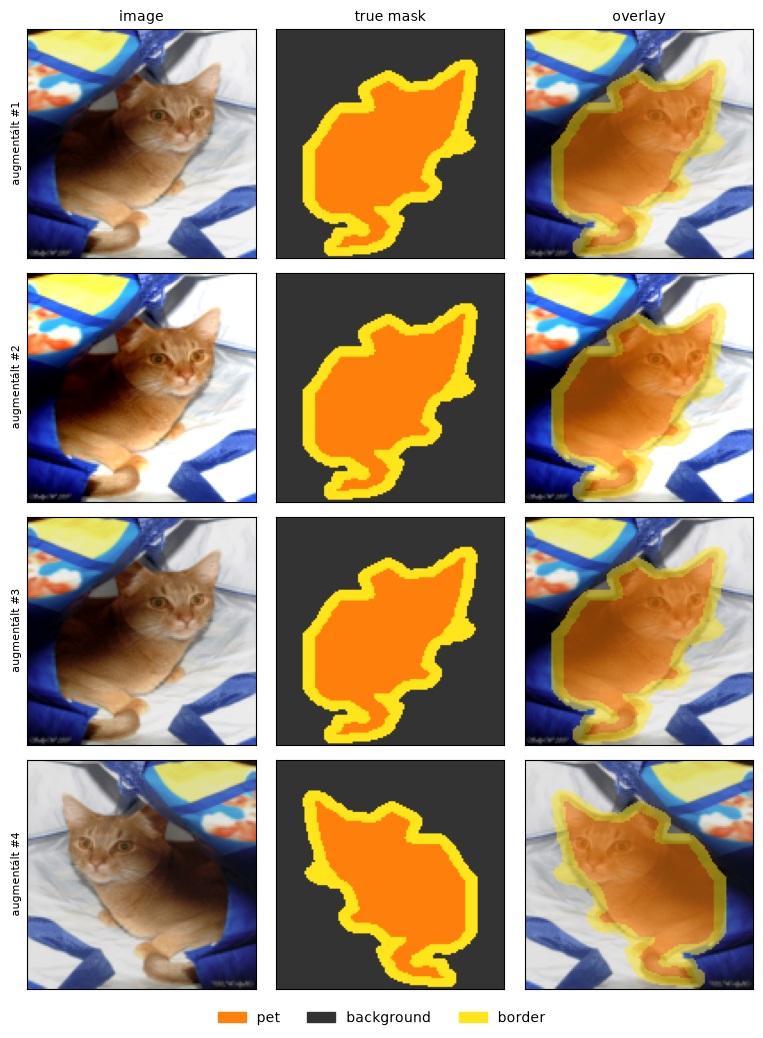

In [6]:
from torchvision.transforms.v2 import functional as TF

if DATA_AVAILABLE:
    raw_image, raw_mask = trainval_base[datasets["train"].indices[0]]
else:
    from unet_pet.data import SampleFolder

    raw_image, raw_mask = SampleFolder()[0]

raw = torch.from_numpy(np.array(raw_mask, dtype=np.uint8))[None].float()
size = [cfg.data.img_size] * 2
nearest = TF.resize(raw, size, interpolation=TF.InterpolationMode.NEAREST)
bilinear = TF.resize(raw, size, interpolation=TF.InterpolationMode.BILINEAR)
print("Eredeti trimap értékek:          ", sorted(torch.unique(raw).int().tolist()))
print("NEAREST átméretezés után:        ", sorted(torch.unique(nearest).int().tolist()))
n_fake = int((bilinear != bilinear.round()).sum())
print(f"BILINEAR után nem egész értékű pixelek: {n_fake} (ezek nem létező címkék lennének)")

train_tf = build_transform(cfg, train=True)
set_seed(cfg.seed)
augmented = [train_tf(raw_image, raw_mask) for _ in range(4)]
aug_images = torch.stack([img for img, _ in augmented])
aug_masks = torch.stack([trimap_to_labels(m) for _, m in augmented])
show_predictions(
    aug_images,
    aug_masks,
    mean=cfg.data.mean,
    std=cfg.data.std,
    n=4,
    titles=[f"augmentált #{i + 1}" for i in range(4)],
)
plt.show()

A fenti négy sor **ugyanannak** a tanítóképnek négy véletlen augmentált változata. Ahol a
kép tükrözött, ott a maszk is pontosan ugyanúgy tükröződött, a színek pedig csak a képen
változnak.

## 4. A modell: U-Net

### Miért U-Net, és miért nem órán vett modell?

A tárgy követelménye, hogy a modell és a feladat párosa ne egyezzen az órán vettekkel. Órán
osztályozó hálók (pl. ResNet) és autoencoderek szerepeltek, szegmentálás nem. A
**U-Net** (Ronneberger, Fischer és Brox, 2015) a szemantikus szegmentálás egyik
alaparchitektúrája: eredetileg orvosi képekre tervezték, ahol kevés a tanítóadat, ezért egy
néhány ezer képes adathalmazon nulláról is jól tanítható. A hálót **saját magunk építjük fel
nulláról** (`unet_pet/model.py`), előtanított súlyok nélkül.

### Felépítés

```
bemenet 3 x 128 x 128
 │
 ├─ DoubleConv ─────────────────────────────── 32 x 128 x 128 ─────────┐ skip
 │   └─ Down (maxpool + DoubleConv) ────────── 64 x  64 x  64 ───────┐  │
 │       └─ Down ───────────────────────────  128 x  32 x  32 ─────┐  │  │
 │           └─ Down ───────────────────────  256 x  16 x  16 ───┐  │  │  │
 │               └─ Down (bottleneck) ──────  512 x   8 x   8    │  │  │  │
 │               ┌─ Up (ConvTranspose + concat + DoubleConv) ◄───┘  │  │  │
 │           ┌─ Up ◄────────────────────────────────────────────────┘  │  │
 │       ┌─ Up ◄───────────────────────────────────────────────────────┘  │
 │   ┌─ Up ◄──────────────────────────────────────────────────────────────┘
 └─ 1x1 conv ─► kimenet 3 x 128 x 128 (osztályonkénti logitok minden pixelre)
```

- **Encoder (bal ág):** minden szinten két 3x3-as konvolúció (BatchNorm + ReLU után), majd
  2x2-es max-pooling. A térbeli felbontás minden szinten feleződik, a csatornaszám duplázódik:
  a háló egyre absztraktabb, egyre nagyobb képrészletet „látó” jellemzőket tanul
  (*mi* van a képen).
- **Bottleneck:** a legkisebb felbontás (8x8), a legtöbb csatorna (512).
- **Decoder (jobb ág):** transzponált konvolúcióval visszaduplázza a felbontást, és ezt
  összefűzi (konkatenálja) az encoder azonos szintjének kimenetével.
- **Skip kapcsolatok:** ez a U-Net lényege. A pooling elveszíti a pontos pozíció-információt
  (*hol* van az él). A skip kapcsolatok a nagy felbontású encoder-jellemzőket közvetlenül
  átadják a decodernek, így a kimeneti maszk határai élesek maradnak.
- **Kimenet:** 1x1-es konvolúció, ami minden pixelre 3 osztály-logitot ad; a predikció
  ezek `argmax`-a.

A konvolúciók `padding=1`-gyel dolgoznak, így a kimenet mérete megegyezik a bemenetével
(az eredeti cikk „valid” konvolúcióival szemben ez egyszerűsíti a maszkokkal való
összevetést). A konvolúciók után BatchNorm áll, ezért a konvolúcióknak nincs bias tagja
(a BatchNorm eltolása ezt úgyis kiváltja).

In [7]:
model = build_model(cfg).to(device)
widths = [cfg.model.base_channels * 2**i for i in range(cfg.model.depth + 1)]
sizes = [cfg.data.img_size // 2**i for i in range(cfg.model.depth + 1)]
display(
    Markdown(
        "| szint | csatornák | térbeli méret |\n|---|---|---|\n"
        + "\n".join(
            f"| {'bottleneck' if i == cfg.model.depth else i} | {w} | {s} x {s} |"
            for i, (w, s) in enumerate(zip(widths, sizes, strict=True))
        )
    )
)

with torch.no_grad():
    dummy = torch.zeros(2, cfg.model.in_channels, cfg.data.img_size, cfg.data.img_size)
    out = model(dummy.to(device))
print(f"bemenet: {tuple(dummy.shape)} -> kimenet: {tuple(out.shape)}")
print(f"tanítható paraméterek száma: {count_parameters(model):,}".replace(",", " "))

| szint | csatornák | térbeli méret |
|---|---|---|
| 0 | 32 | 128 x 128 |
| 1 | 64 | 64 x 64 |
| 2 | 128 | 32 x 32 |
| 3 | 256 | 16 x 16 |
| bottleneck | 512 | 8 x 8 |

bemenet: (2, 3, 128, 128) -> kimenet: (2, 3, 128, 128)
tanítható paraméterek száma: 7 763 107


## 5. Tanítás

### Loss: CrossEntropy + Dice

$$\mathcal{L} = \mathcal{L}_{CE} + w \cdot \mathcal{L}_{Dice}, \qquad
\mathcal{L}_{Dice} = 1 - \frac{1}{C}\sum_{c=1}^{C}
\frac{2\sum_i p_{i,c}\, g_{i,c} + s}{\sum_i p_{i,c} + \sum_i g_{i,c} + s}$$

ahol $p_{i,c}$ az $i$-edik pixel softmax-valószínűsége a $c$ osztályra, $g_{i,c}$ a
one-hot címke, $s = 1$ egy simító tag, $w$ = `dice_weight` = 1.

- A **CrossEntropy** pixelenként stabil, jól viselkedő gradienst ad, de minden pixel
  egyforma súllyal számít, így a nagy háttérosztály dominál.
- A **Dice loss** osztályonként a jósolt és a valódi terület átfedését méri, és az osztályokat
  egyenlő súllyal átlagolja. Így a vékony határ osztály ugyanannyit számít, mint a háttér;
  ráadásul közeli rokona a kiértékeléshez használt IoU-nak.
- A kettő összege ötvözi a CE stabilitását és a Dice kiegyensúlyozottságát. Hogy ez valóban
  segít-e, azt a 8. fejezetben egy csak CE-vel tanított modellel vetjük össze.

A Dice-t a teljes batch pixelein számoljuk osztályonként (nem képenként), mert a határ
osztály egy-egy képen kevés pixelből áll, és a képenkénti Dice nagyon zajos lenne.

### Optimalizálás

- **Adam** optimalizáló (adaptív, paraméterenkénti lépésköz; kis weight decay
  regularizációval).
- **ReduceLROnPlateau** ütemező: ha a *validációs mIoU* `patience` epochon át nem javul, a
  tanulási ráta a felére csökken. Azért a mIoU-hoz kötjük (és nem a val loss-hoz), mert a
  modellt is ezzel választjuk ki.
- **Modellválasztás:** minden epoch után kiértékelünk a validációs spliten; a legjobb
  validációs mIoU-jú epoch súlyai kerülnek a `models/unet_pet_best.pt` fájlba. Ez egyfajta
  *early stopping*: a túltanult későbbi epochok nem rontják el a végeredményt.
- **Checkpoint és folytatás:** minden epoch után teljes állapotmentés (`last.pt`: modell,
  optimizer, scheduler, history), ebből egy megszakadt tanítás bitre azonosan folytatható.
- **Kísérletkövetés:** a loss-ok, a metrikák, a tanulási ráta és néhány validációs kép
  predikciója minden epochban TensorBoardba kerül.

A tényleges hiperparaméterek a konfigurációból:

In [8]:
t = cfg.train
rows = [
    ("epochok száma", t.epochs),
    ("batch méret", t.batch_size),
    ("optimizer", "Adam"),
    ("kezdő tanulási ráta", t.lr),
    ("weight decay", t.weight_decay),
    ("ütemező", f"{t.scheduler} (szorzó {t.scheduler_factor}, türelem {t.scheduler_patience})"),
    ("loss", f"CE + {t.dice_weight} * Dice"),
    ("képméret", f"{cfg.data.img_size} x {cfg.data.img_size}"),
    ("augmentáció", f"tükrözés p={cfg.data.hflip_prob}, színtorzítás {cfg.data.color_jitter}"),
    ("seed", cfg.seed),
]
display(
    Markdown(
        "| hiperparaméter | érték |\n|---|---|\n" + "\n".join(f"| {k} | {v} |" for k, v in rows)
    )
)

| hiperparaméter | érték |
|---|---|
| epochok száma | 25 |
| batch méret | 16 |
| optimizer | Adam |
| kezdő tanulási ráta | 0.001 |
| weight decay | 0.0001 |
| ütemező | reduce_on_plateau (szorzó 0.5, türelem 3) |
| loss | CE + 1.0 * Dice |
| képméret | 128 x 128 |
| augmentáció | tükrözés p=0.5, színtorzítás [0.2, 0.2, 0.2, 0.0] |
| seed | 42 |

### Tanítás vagy betöltés

`TRAIN = True` esetén az alábbi cella lefuttatja a teljes tanítást a `fit` függvénnyel
(ugyanaz, mint a `python -m unet_pet.train` parancs), majd a legjobb súlyokat exportálja.
Alapesetben (`TRAIN = False`) a repóban mellékelt, már betanított súlyokat tölti be. A
súlyfájl egy sima `state_dict`, amit `weights_only=True`-val töltünk be (ez nem futtat
tetszőleges kódot a fájlból).

A mellékelt modell tanítása CPU-n (AMD Ryzen 7 8845HS, 8 mag) 25 epoch alatt kb. 1 óra
50 percig tartott.

In [9]:
weights_path = cfg.paths.best_weights
if TRAIN:
    if not DATA_AVAILABLE:
        raise RuntimeError("A tanításhoz le kell tölteni az adathalmazt (nincs internet?).")
    fit(cfg, run_name="notebook")

if not weights_path.is_file():
    raise FileNotFoundError(
        f"Nem található a súlyfájl: {rel(weights_path)}. Futtasd a notebookot TRAIN = True "
        "beállítással, vagy: python -m unet_pet.train"
    )
model = load_trained_model(cfg, weights_path, device)
print(f"Betöltve: {rel(weights_path)} ({weights_path.stat().st_size / 2**20:.1f} MB)")

Betöltve: models/unet_pet_best.pt (29.7 MB)


### Tanulási görbék

A tanítás minden epochjának eredményeit a `models/unet_pet_history.json` tartalmazza (a
súlyokkal együtt kerül a repóba).

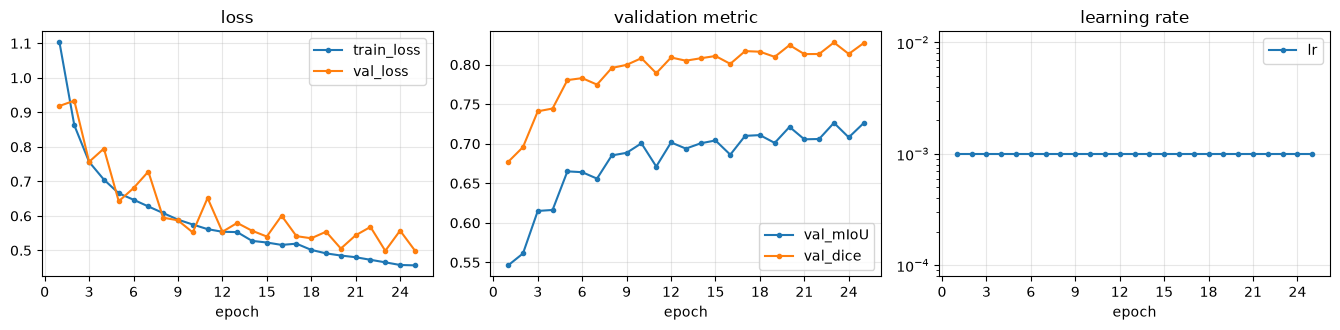

legjobb epoch: 23 / 25 | val mIoU: 0.7264 | train loss: 0.4655 | val loss: 0.4988


In [10]:
history = json.loads(cfg.paths.history.read_text(encoding="utf-8"))
plot_history(history)
plt.show()

best = history["best_epoch"]
print(
    f"legjobb epoch: {best} / {len(history['val_mIoU'])} | "
    f"val mIoU: {history['val_mIoU'][best - 1]:.4f} | "
    f"train loss: {history['train_loss'][best - 1]:.4f} | "
    f"val loss: {history['val_loss'][best - 1]:.4f}"
)

**Értelmezés.**

- A tanító loss egyenletesen csökken, a validációs loss nagyjából követi, és a kettő
  közötti rés végig kicsi: **nincs számottevő túltanulás**. Ebben az augmentáció és a
  validáción alapuló modellválasztás is szerepet játszik.
- A validációs mIoU az első epochok gyors emelkedése után lassabban, de a tanítás végéig
  javul; a legjobb érték a 23. epochban született.
- A validációs görbe epochról epochra ingadozik. Ennek oka, hogy a tanulási ráta végig a
  kezdő `1e-3` maradt: az ütemező csak akkor felez, ha a val mIoU 3 epochon át nem javul,
  de mindig jött egy új csúcs 1–3 epochon belül. Az ingadozás és a még emelkedő trend azt
  jelzi, hogy **hosszabb tanítással** (és így a tanulási ráta csökkenésével) valószínűleg
  még javítható lenne az eredmény.

### TensorBoard

A tanítás részletes naplója (loss-komponensek, osztályonkénti IoU, tanulási ráta, és a
validációs predikciók képei epochonként) TensorBoardban nézhető meg. A napló a `runs/`
mappába kerül, ami a mérete miatt nem része a repónak; saját tanítás után így nyitható meg:

```
tensorboard --logdir runs
```

vagy a notebookon belül:

```
%load_ext tensorboard
%tensorboard --logdir runs
```

## 6. Kiértékelés a teszt spliten

### Metrikák

Minden metrikát a teljes split **konfúziós mátrixából** számolunk ($TP$, $FP$, $FN$
osztályonként, az összes tesztkép összes pixelén), nem batch-átlagok átlagaként:

- **IoU** (Intersection over Union, Jaccard-index) osztályonként:
  $IoU_c = \dfrac{TP_c}{TP_c + FP_c + FN_c}$, azaz a jósolt és a valódi terület metszete
  osztva az uniójukkal. **mIoU** = a 3 osztály IoU-jának átlaga — ez a **fő metrika**.
- **Dice** osztályonként: $Dice_c = \dfrac{2\,TP_c}{2\,TP_c + FP_c + FN_c}$, és ezek átlaga.
- **Pixelpontosság:** a helyesen osztályozott pixelek aránya (a 2. fejezet szerint
  félrevezető, csak tájékoztató jellegű).

**Baseline.** Hogy a számoknak legyen viszonyítási pontja, ugyanezeket a metrikákat
kiszámoljuk egy triviális „modellre” is, amely **minden pixelre hátteret jósol**.

Az alábbi cella (`RUN_TEST_EVAL = True` esetén) élőben kiértékeli a modellt a teljes
hivatalos teszt spliten, és az eredményt a `results/test_metrics.json` fájlba írja.
Adathalmaz nélkül (vagy `RUN_TEST_EVAL = False` esetén) a mentett eredményfájlt tölti be.

In [11]:
LIVE_EVAL = RUN_TEST_EVAL and DATA_AVAILABLE
if LIVE_EVAL:
    evaluation = run_evaluation(
        cfg, weights_path, split="test", limit=EVAL_LIMIT, device=device, progress=False
    )
    report = evaluation["report"]
    if evaluation["json_path"] is not None:
        print(f"Eredmény mentve: {rel(evaluation['json_path'])}")
    else:
        print(f"EVAL_LIMIT = {EVAL_LIMIT}: próbafuttatás, az eredmény nem került mentésre.")
else:
    report = json.loads(metrics_path(cfg).read_text(encoding="utf-8"))
    print(
        "A mentett kiértékelés jelenik meg: "
        f"{rel(metrics_path(cfg))} (élő kiértékelés kikapcsolva vagy nincs adathalmaz)."
    )

m, b = report["model"], report["baseline"]


def fmt(value):
    return "–" if value is None or value != value else f"{value:.4f}"


rows = [
    ("**mIoU**", m["mIoU"], b["mIoU"]),
    ("Dice (átlag)", m["dice"], b["dice"]),
    ("pixelpontosság", m["pixel_acc"], b["pixel_acc"]),
]
rows += [
    (f"IoU – {name}", mv, bv)
    for name, mv, bv in zip(CLASS_NAMES, m["iou_per_class"], b["iou_per_class"], strict=True)
]
rows += [
    (f"Dice – {name}", mv, bv)
    for name, mv, bv in zip(CLASS_NAMES, m["dice_per_class"], b["dice_per_class"], strict=True)
]
display(
    Markdown(
        f"**Teszt split, {report['n_images']} kép**\n\n"
        "| metrika | U-Net | baseline (mindig háttér) |\n|---|---|---|\n"
        + "\n".join(f"| {name} | {fmt(mv)} | {fmt(bv)} |" for name, mv, bv in rows)
    )
)

Eredmény mentve: results/test_metrics.json


**Teszt split, 3669 kép**

| metrika | U-Net | baseline (mindig háttér) |
|---|---|---|
| **mIoU** | 0.7371 | 0.1926 |
| Dice (átlag) | 0.8367 | 0.2441 |
| pixelpontosság | 0.8997 | 0.5778 |
| IoU – pet | 0.8130 | 0.0000 |
| IoU – background | 0.8973 | 0.5778 |
| IoU – border | 0.5009 | 0.0000 |
| Dice – pet | 0.8968 | 0.0000 |
| Dice – background | 0.9458 | 0.7324 |
| Dice – border | 0.6675 | 0.0000 |

**Értelmezés.**

- A U-Net mIoU-ja a teszt spliten 0,737, a baseline-é 0,193; a modell tehát **messze
  túlteljesíti** a triviális megoldást. A baseline pixelpontossága közben 58% körüli,
  ami jól mutatja, miért nem ez a fő metrika.
- A teszteredmény a validációs mIoU-hoz (0,726) nagyon közel van, sőt kicsit jobb. Ez azt
  jelzi, hogy a validációs halmazon történt modellválasztás nem illesztett túl a validációs
  képekre, és a modell jól általánosít a soha nem látott tesztképekre.
- Osztályonként: a **kisállat** (IoU kb. 0,81) és a **háttér** (kb. 0,90) jól
  szegmentálható, a **határ** osztály (kb. 0,50) a leggyengébb. A határ csak néhány pixel
  széles sáv, ahol már 1–2 pixeles eltolódás is nagy relatív hibát jelent; ráadásul a
  címkézése maga is bizonytalan (éppen ezért „bizonytalan sáv” a trimapben).

### Konfúziós mátrix

Soronként normalizálva: a sor a valódi osztály, az oszlop a jósolt. Az átló az osztályonkénti
*recall* (a valódi pixelek hány százalékát találta el a modell), a többi cella megmutatja,
**mivel** keveri össze az adott osztályt.

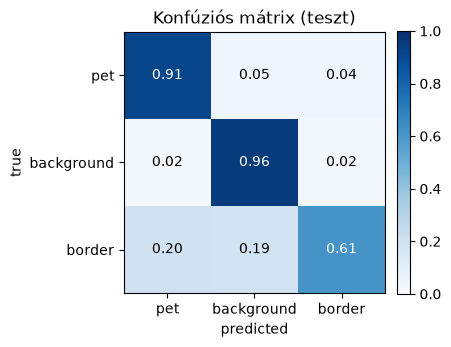

In [12]:
plot_confusion_matrix(report["model"]["confusion_matrix"], title="Konfúziós mátrix (teszt)")
plt.show()

A kisállat és a háttér pixeleinek túlnyomó része helyes osztályba kerül, és a kettőt a modell
ritkán keveri össze egymással. A határ pixeleinek viszont jelentős része a kisállat vagy a
háttér osztályba kerül, nagyjából egyenlő arányban: a modell megtalálja a körvonalat, de a
sáv pontos szélességét és helyét nem mindig. Ez összhangban van azzal, hogy a határ
lényegében az átmenet a két nagy osztály között.

## 7. Vizuális eredmények és hibaelemzés

A számok mellett érdemes megnézni magukat a predikciókat is. Minden sorban: az eredeti kép,
a valódi maszk, a modell predikciója, és a predikció a képre vetítve. A sorok bal oldalán a
kép neve (fajta + sorszám) és a képenkénti mIoU áll.

### Véletlen tesztképek

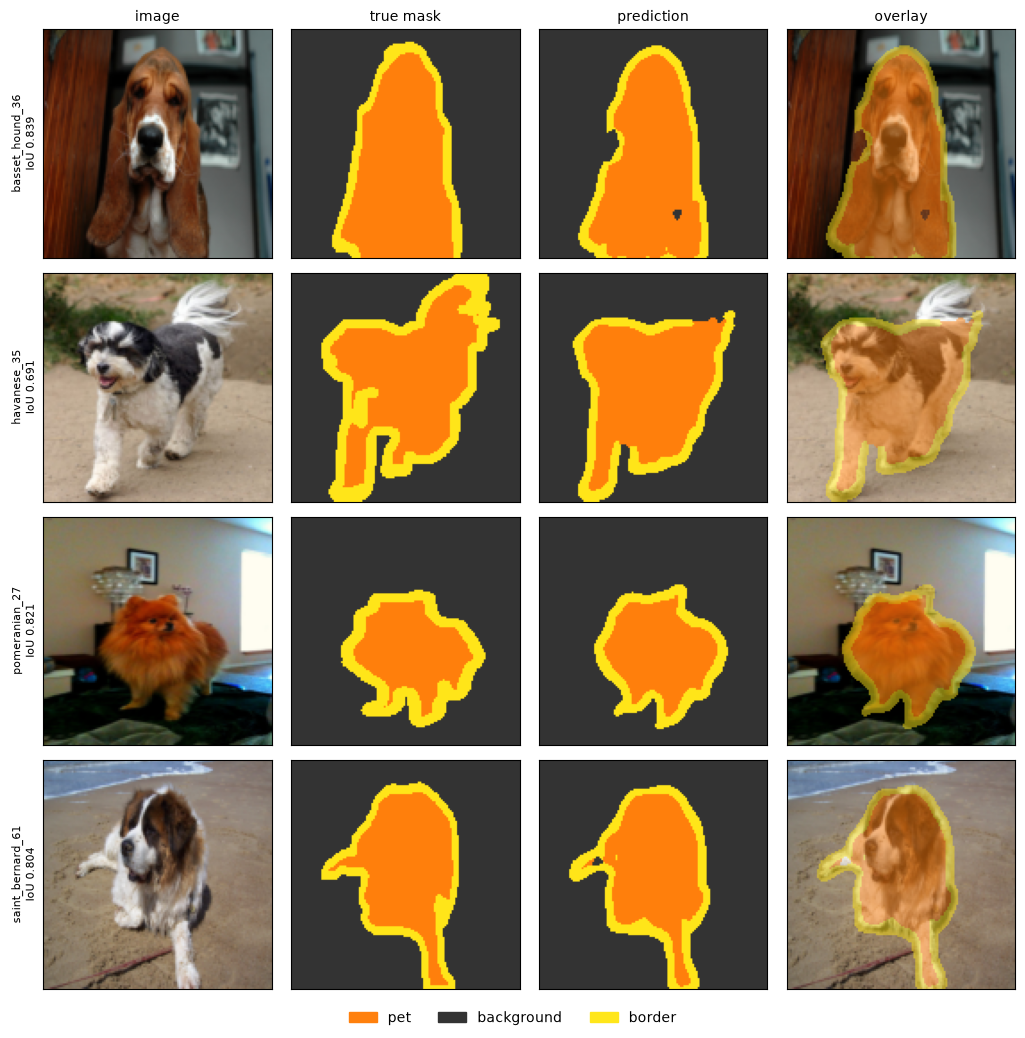

In [13]:
if DATA_AVAILABLE:
    test_ds = make_eval_dataset(cfg, "test", limit=EVAL_LIMIT if LIVE_EVAL else None)
    names = report["per_image_iou"]["names"]
    ious = report["per_image_iou"]["iou"]
    rng = np.random.default_rng(cfg.seed)
    idx = sorted(rng.choice(len(test_ds), size=4, replace=False).tolist())
    imgs, msks = map(torch.stack, zip(*(test_ds[i] for i in idx), strict=True))
    with torch.no_grad():
        preds = model(imgs.to(device)).argmax(dim=1).cpu()
    show_predictions(
        imgs,
        msks,
        preds,
        mean=cfg.data.mean,
        std=cfg.data.std,
        n=4,
        titles=[f"{names[i]}\nIoU {ious[i]:.3f}" for i in idx],
    )
    plt.show()
else:
    test_ds = None
    print(
        "Az adathalmaz nem érhető el: a tesztképek helyett a fejezet végén a "
        "sample_data/ képein látható a predikció."
    )

### Képenkénti IoU eloszlása, a legjobb és a legrosszabb képek

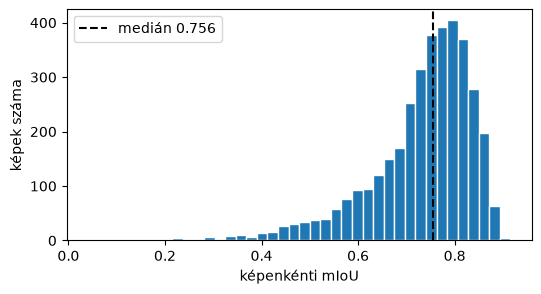

A képek 28.1%-ának 0.8 feletti, 4.7%-ának 0.5 alatti a mIoU-ja.


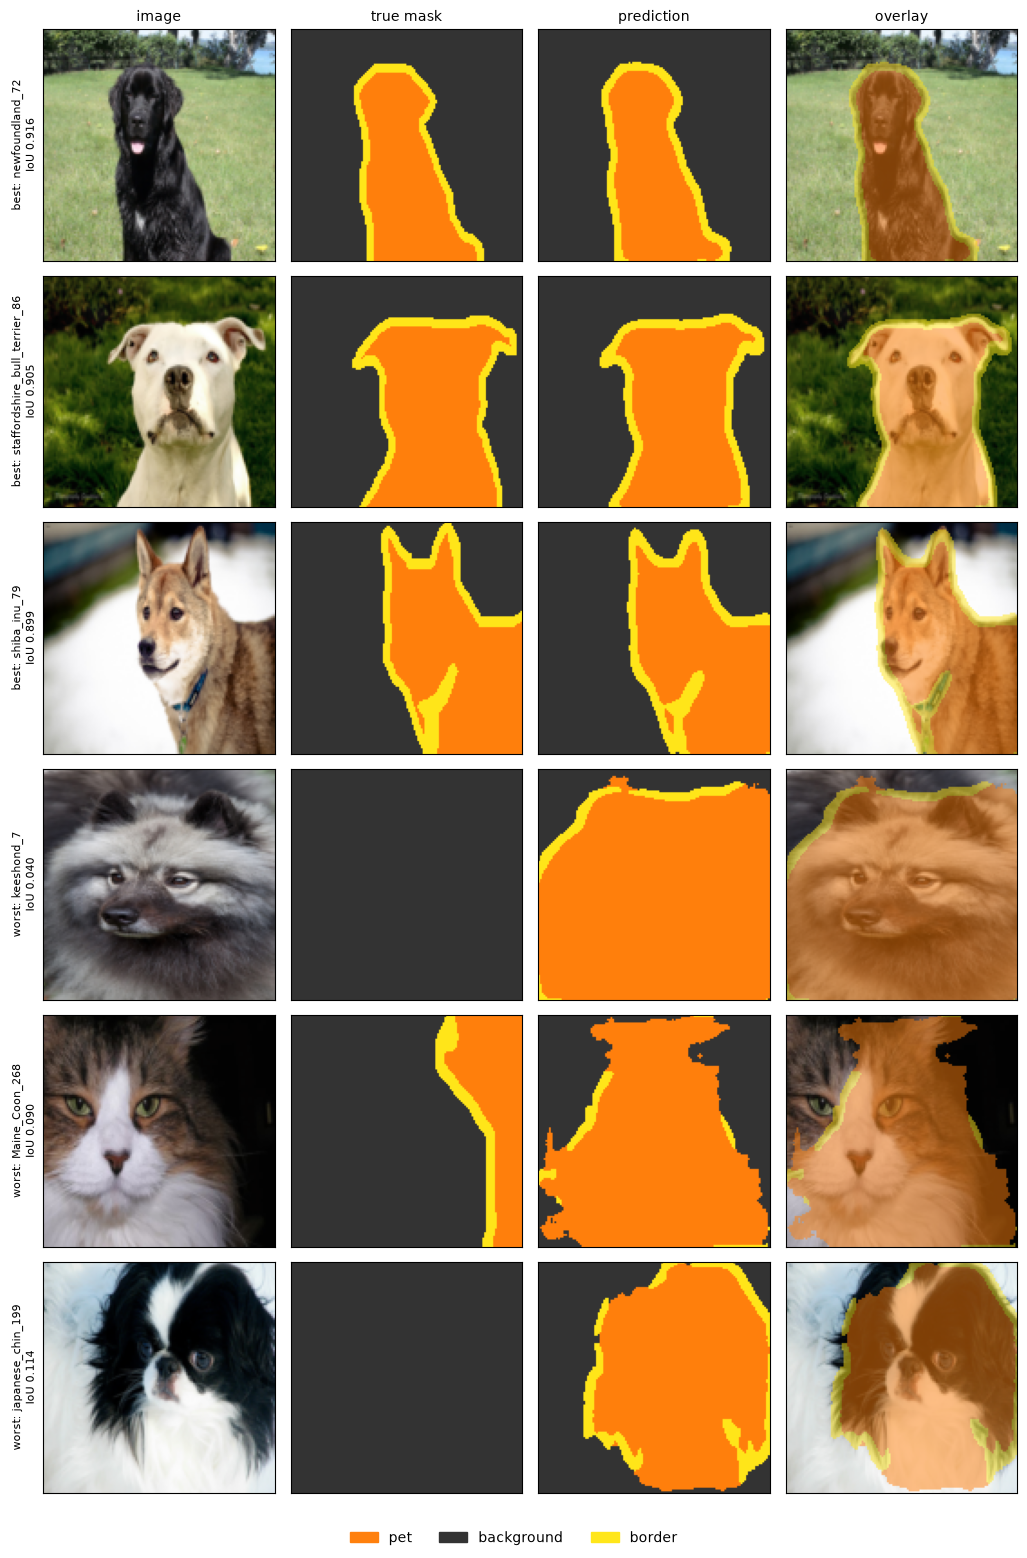

In [14]:
ious = np.array([v for v in report["per_image_iou"]["iou"] if v is not None])
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(ious, bins=40, color="tab:blue", edgecolor="white")
ax.axvline(np.median(ious), color="black", linestyle="--", label=f"medián {np.median(ious):.3f}")
ax.set_xlabel("képenkénti mIoU")
ax.set_ylabel("képek száma")
ax.legend()
plt.show()
print(
    f"A képek {(ious >= 0.8).mean():.1%}-ának 0.8 feletti, {(ious < 0.5).mean():.1%}-ának "
    "0.5 alatti a mIoU-ja."
)

if test_ds is not None:
    examples_figure(model, test_ds, report, cfg, device)
    plt.show()

A felső három sor a legjobb, az alsó három a legrosszabb tesztkép. A legjobb képeken a
predikció szinte pixelpontosan követi a valódi maszkot, a határsávval együtt: jól elkülönülő,
egyszínű háttér előtt álló, nagyméretű állatok.

A legrosszabb képek vizsgálata viszont tanulságos: ezeken **nem a modell téved, hanem a
címke hibás**. Több képnél a valódi maszk teljesen üres (csupa háttér), holott a képet egy
kutya vagy macska tölti ki — a modell helyesen megtalálja az állatot, a metrika mégis
majdnem nulla IoU-t ad rá. Máshol a maszk csak az állat egy kis részét jelöli. Az
Oxford-IIIT Pet adathalmaz kézi annotációjában ismerten vannak ilyen hibák.

In [15]:
empty = report.get("empty_pet_masks", [])
print(f"Olyan tesztkép, amelynek a valódi maszkjában egyetlen 'pet' pixel sincs: {len(empty)} db")
if empty:
    print("  " + ", ".join(f"{e['name']} (IoU {e['iou']:.3f})" for e in empty))
    all_ious = np.array(report["per_image_iou"]["iou"], dtype=float)
    keep = np.ones(len(all_ious), dtype=bool)
    keep[[e["index"] for e in empty]] = False
    print(f"Képenkénti átlagos mIoU az összes képen:            {np.nanmean(all_ious):.4f}")
    print(f"Képenkénti átlagos mIoU a hibás maszkok nélkül:     {np.nanmean(all_ious[keep]):.4f}")

Olyan tesztkép, amelynek a valódi maszkjában egyetlen 'pet' pixel sincs: 7 db
  Egyptian_Mau_20 (IoU 0.157), japanese_chin_199 (IoU 0.114), keeshond_7 (IoU 0.040), Persian_259 (IoU 0.135), saint_bernard_60 (IoU 0.294), saint_bernard_78 (IoU 0.225), wheaten_terrier_195 (IoU 0.294)
Képenkénti átlagos mIoU az összes képen:            0.7300
Képenkénti átlagos mIoU a hibás maszkok nélkül:     0.7311


Ezeket a képeket **nem hagyjuk ki** a hivatalos eredményből — a teszt split úgy értékelendő,
ahogy van, különben az eredményünk nem lenne összevethető másokéval —, de a hibaelemzés része,
hogy tudjuk: a mért érték egy része a címkezajból fakad, nem a modell gyengeségéből. A
címkehibákon kívüli tipikus valódi hibák (a véletlen példákon és a hisztogram alsó részén):

- **a háttérhez hasonló színű vagy mintázatú bunda**, ahol a körvonal nem egyértelmű;
- **kis méretű, a kép egy sarkában álló állat**: 128 px-es felbontáson kevés pixel jut rá;
- **több tárgy vagy ember a képen**, akiket a modell néha a kisállathoz sorol;
- **a határsáv** szélessége és pontos helye (a konfúziós mátrix utolsó sora).

### Predikció a mellékelt mintaképeken (`sample_data/`)

Ez a cella internet és letöltött adathalmaz nélkül is fut: a repóban mellékelt 8 tesztképen
(4 macska, 4 kutya) mutatja be a modell működését.

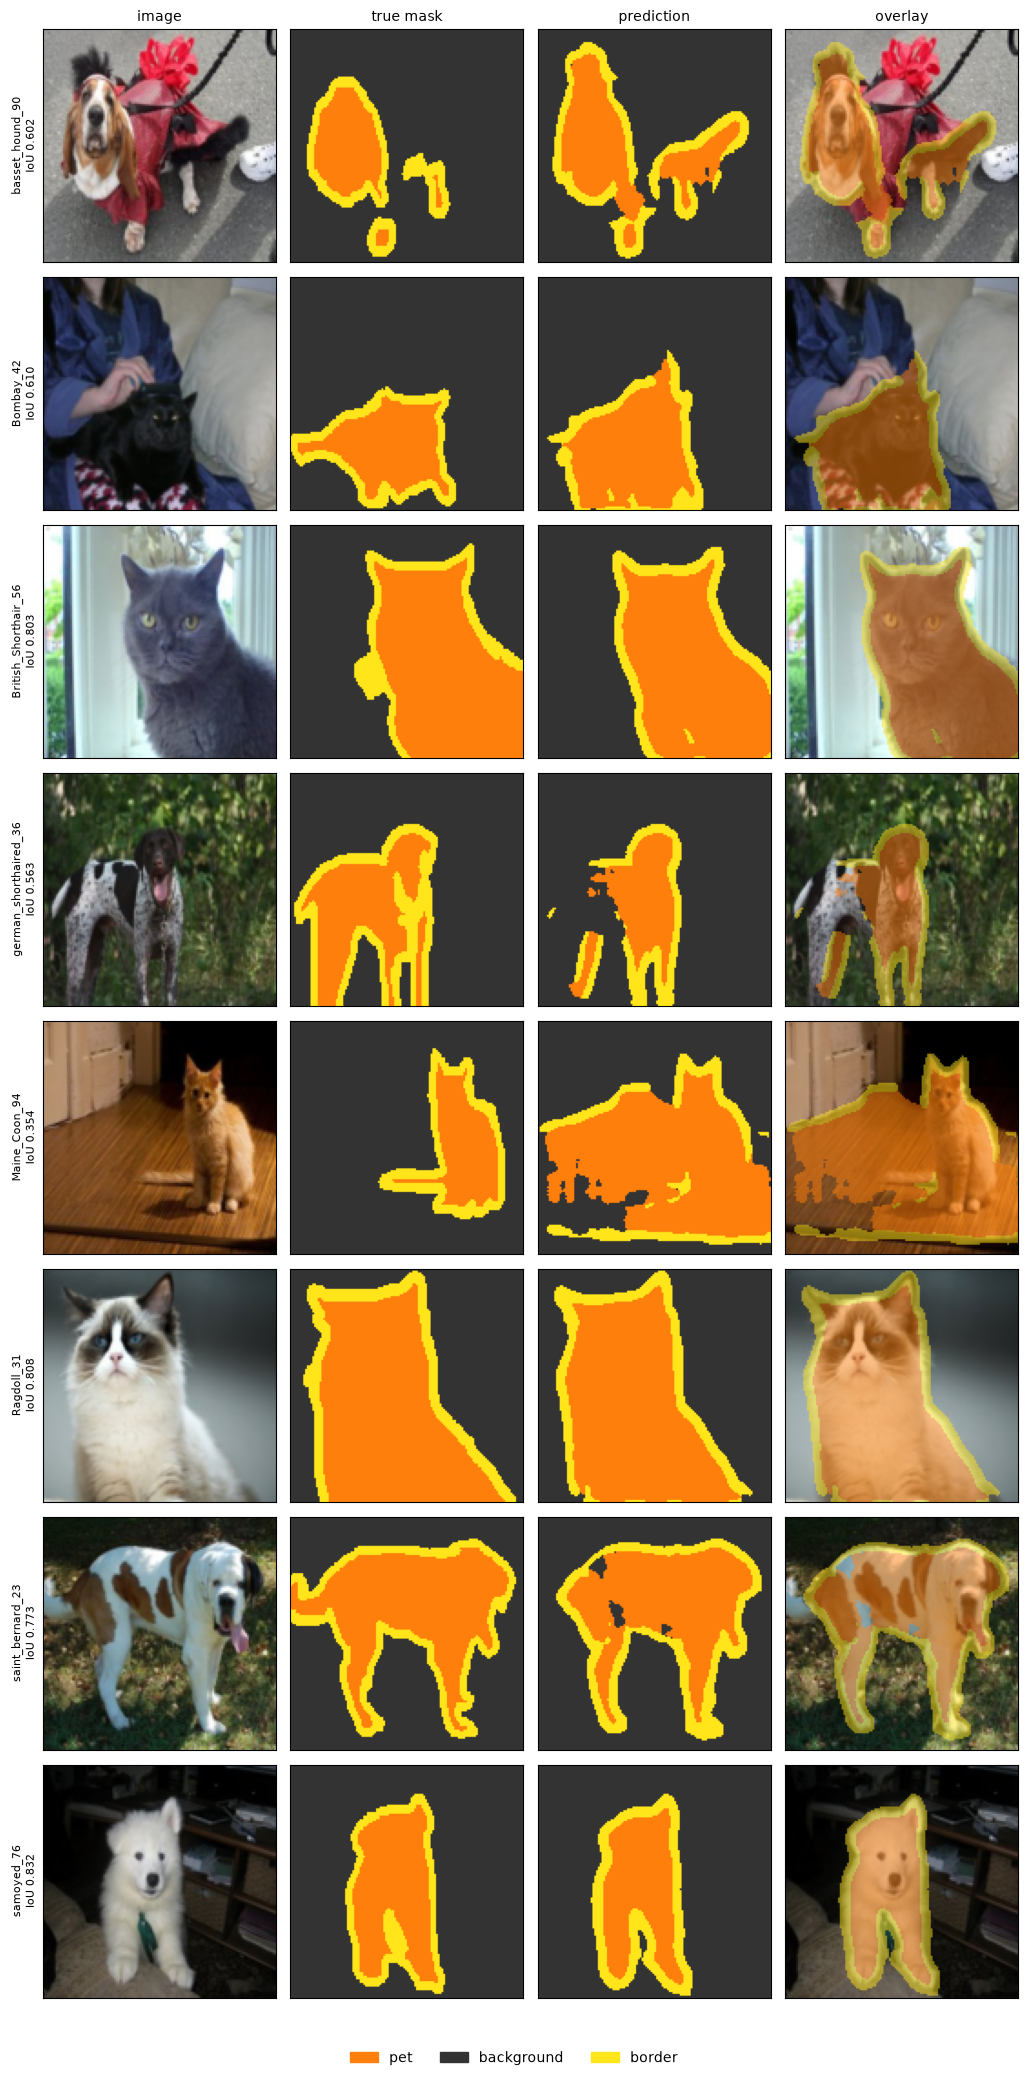

In [16]:
sample_images, sample_masks, sample_names = load_sample_data(cfg)
with torch.no_grad():
    sample_preds = model(sample_images.to(device)).argmax(dim=1).cpu()
sample_ious = per_image_iou(sample_preds, sample_masks, cfg.model.num_classes)
show_predictions(
    sample_images,
    sample_masks,
    sample_preds,
    mean=cfg.data.mean,
    std=cfg.data.std,
    n=len(sample_names),
    titles=[f"{n}\nIoU {v:.3f}" for n, v in zip(sample_names, sample_ious.tolist(), strict=True)],
)
plt.show()

## 8. Kísérletek összevetése: CE + Dice vs. csak CE

A loss választását kísérlettel ellenőrizzük: ugyanazzal a konfigurációval, seeddel és
epochszámmal egy második modellt is tanítottunk, amely **csak CrossEntropy** loss-t használ
(`dice_weight = 0`). Minden más beállítás azonos, így a különbség elsősorban a Dice-tagnak
tulajdonítható. Egy kivétel van, erről az értelmezésnél lesz szó.

```
python -m unet_pet.train --run-name ce_only --no-export --set train.dice_weight=0
python -m unet_pet.evaluate --weights checkpoints/<run>_ce_only/best.pt --tag ce_only
```

A `--no-export` kapcsoló miatt a második tanítás nem írja felül a fő modell súlyait, a
`--tag ce_only` pedig külön fájlba menti a teszt-kiértékelést. A második futás eredményei
a `results/` mappában vannak: `history_ce_only.json` a tanulási görbékkel és
`test_metrics_ce_only.json` a teszt metrikákkal.

| futás | legjobb val mIoU (epoch) | teszt mIoU | teszt IoU pet / background / border |
|---|---|---|---|
| CE + Dice (fő modell) | 0.7264 (23.) | 0.7371 | 0.813 / 0.897 / 0.501 |
| csak CE | 0.7318 (23.) | 0.7350 | 0.819 / 0.901 / 0.485 |

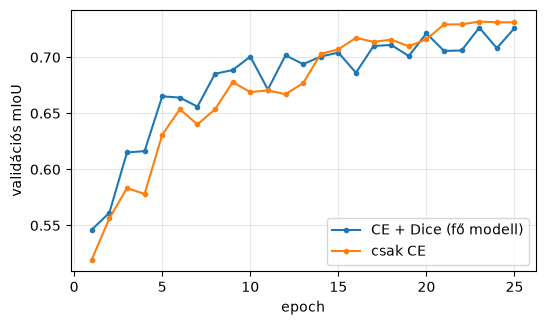

In [17]:
experiments = {
    "CE + Dice (fő modell)": (cfg.paths.history, metrics_path(cfg)),
    "csak CE": (cfg.paths.results / "history_ce_only.json", metrics_path(cfg, tag="ce_only")),
}
loaded = {}
for name, (hist_path, metric_path) in experiments.items():
    if hist_path.is_file() and metric_path.is_file():
        loaded[name] = (
            json.loads(hist_path.read_text(encoding="utf-8")),
            json.loads(metric_path.read_text(encoding="utf-8")),
        )
    else:
        print(f"Hiányzik a(z) '{name}' futás eredménye: {rel(hist_path)} / {rel(metric_path)}")

if loaded:
    lines = [
        "| futás | legjobb val mIoU (epoch) | teszt mIoU | teszt IoU pet / background / border |",
        "|---|---|---|---|",
    ]
    for name, (hist, metr) in loaded.items():
        best_val = max(hist["val_mIoU"])
        epoch = hist.get("best_epoch", int(np.argmax(hist["val_mIoU"])) + 1)
        per_class = " / ".join(f"{v:.3f}" for v in metr["model"]["iou_per_class"])
        lines.append(
            f"| {name} | {best_val:.4f} ({epoch}.) | {metr['model']['mIoU']:.4f} | {per_class} |"
        )
    display(Markdown("\n".join(lines)))

    fig, ax = plt.subplots(figsize=(6, 3.4))
    for name, (hist, _) in loaded.items():
        epochs = range(1, len(hist["val_mIoU"]) + 1)
        ax.plot(epochs, hist["val_mIoU"], marker="o", markersize=3, label=name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("validációs mIoU")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

**Értelmezés.**

- **Összességében a két modell gyakorlatilag egyformán jó.** A teszt spliten a CE + Dice
  modell mIoU-ja kicsit magasabb (0,737 vs. 0,735), a validáción viszont a csak CE-s
  (0,726 vs. 0,732). A különbségek 0,2–0,5 százalékpontosak, és mindkét irányba mutatnak;
  egyetlen seeddel futtatott kísérletpárból ennyi eltérés alapján nem jelenthető ki, hogy
  bármelyik loss jobb.
- **A Dice-tag várt hatása a határ osztályon megjelenik, de kicsi:** a határ IoU-ja a teszt
  spliten 0,485-ről 0,501-re nő (+1,6 százalékpont), cserébe a két nagy osztály (kisállat,
  háttér) IoU-ja néhány tized ponttal csökken. Ez megfelel a várakozásnak: a Dice az
  osztályokat egyenlő súllyal kezeli, így a ritka határ osztály nagyobb szerepet kap,
  mint a sok háttérpixel által dominált CrossEntropyban.
- **Zavaró tényező: a tanulási ráta ütemezése.** Bár a konfiguráció azonos volt, a két futás
  menete eltért. A csak CE-s futásban a validációs mIoU kétszer is 3 epochon át stagnált,
  ezért az ütemező a 14. és a 21. epochban felezte a tanulási rátát, és a görbe mindkétszer
  láthatóan megugrott. A CE + Dice futásban a ráta végig `1e-3` maradt. A csak CE-s modell
  validációs előnye tehát valószínűleg részben a kisebb tanulási rátának köszönhető, nem
  magának a loss-nak.
- **Döntés:** a fő modell a CE + Dice marad. A teszt spliten mért, a modellválasztástól
  független eredménye nem rosszabb, és a gyengébb határ osztályon jobb. A kísérlet
  tanulsága inkább az, hogy ezen a felbontáson és tanítási hosszon a loss választása
  másodlagos a tanulási ráta ütemezéséhez képest. Megbízható összevetéshez több seeddel
  és hosszabb, mindkét futásban azonos ütemezéssel kellene tanítani.

## 9. Összegzés és korlátok

### Eredmények

- Nulláról épített, kb. 7,8 millió paraméteres **U-Net**-et tanítottunk 3 osztályos
  (kisállat / háttér / határ) szemantikus szegmentálásra az Oxford-IIIT Pet adathalmazon.
- A hivatalos teszt spliten a **mIoU 0,737** (kisállat 0,81, háttér 0,90, határ 0,50 IoU), a
  „mindig háttér” baseline 0,193-as értékével szemben.
- A teszteredmény a validációs eredménnyel összhangban van, túltanulásnak nincs jele.
- Az összehasonlító kísérletben a csak CrossEntropyval tanított modell összesítve
  gyakorlatilag ugyanilyen jó lett (teszt mIoU 0,735). A Dice-tag a határ osztályon hozott
  kis javulást (IoU 0,485 → 0,501).

### Mit tanultunk

- Szegmentálásnál a **metrika megválasztása** kritikus: a pixelpontosság egy semmit sem
  felismerő modellnek is 58%-ot ad, a mIoU viszont csak a valódi teljesítményt jutalmazza.
- A **skip kapcsolatok** teszik lehetővé, hogy a kimeneti maszk határai élesek legyenek a
  többszöri lefelé mintavételezés ellenére.
- Az adat-előkészítés apró részletei (a maszk `NEAREST` átméretezése, a kép és a maszk
  szinkron augmentációja, a címkék 0-tól indexelése) a helyes működés feltételei: ezek
  hibája nem dob hibaüzenetet, csak csendben rontja az eredményt — ezért tesztek ellenőrzik őket.
- Az adathalmaz **címkéi sem tökéletesek**: a legrosszabb „hibák” egy része annotációs hiba.
- Egy kísérlet kimenetelét a változtatott paraméteren kívül más is befolyásolhatja. A loss
  cseréje a tanulási ráta ütemezését is megváltoztatta, így egyetlen futáspárból a hatásuk
  nem választható szét.

### Korlátok és továbbfejlesztési lehetőségek

- **Felbontás:** 128 x 128 px-en a vékony határsáv és a kis állatok részletei elvesznek;
  nagyobb (pl. 256 px-es) bemenettel a határ osztály IoU-ja várhatóan javulna, cserébe kb.
  négyszeres számítási igénnyel.
- **Tanítási idő és ütemezés:** a fő modellnél a tanulási ráta 25 epoch alatt egyszer sem
  csökkent, és a validációs mIoU még emelkedett. A csak CE-s futásban viszont mindkét
  rátafelezés után láthatóan javult az eredmény. Hosszabb tanítás vagy rögzített
  (pl. cosine) ütemezés ezért valószínűleg további javulást hozna.
- **Kísérletek megbízhatósága:** az összehasonlítás egyetlen seeddel készült; több seed
  átlaga és szórása mutatná meg, mekkora különbség tekinthető valódinak.
- **Augmentáció:** véletlen kivágás és nagyítás, kis forgatás tovább csökkenthetné a
  túltanulás kockázatát nagyobb modellnél.
- **Határ osztály:** súlyozott loss (pl. Focal loss vagy osztálysúlyok) célzottan javíthatná.
- **Címkezaj:** a hibás maszkú tanítóképek kiszűrése (pl. a nagy loss-ú képek kézi
  ellenőrzése) tisztább tanítóadatot adna.
- Előtanított encoder (pl. ImageNet-en tanított ResNet) jelentősen javítana, de a feladat
  kifejezetten a nulláról épített háló volt.

## 10. Reprodukálás

Minden parancs a repó gyökeréből futtatandó (telepítés után, lásd a `README.md`-t):

| Lépés | Parancs | Futásidő (CPU, 8 mag) |
|-------|---------|------------------------|
| telepítés | `pip install -r requirements.txt` | néhány perc |
| tanítás (fő modell) | `python -m unet_pet.train --run-name ce_dice` | kb. 1 ó 50 p |
| összehasonlító tanítás | `python -m unet_pet.train --run-name ce_only --no-export --set train.dice_weight=0` | kb. 1 ó 50 p |
| kiértékelés (teszt) | `python -m unet_pet.evaluate --figures` | kb. 4 p |
| kiértékelés (összehasonlító modell) | `python -m unet_pet.evaluate --weights checkpoints/<run>_ce_only/best.pt --tag ce_only` | kb. 4 p |
| TensorBoard | `tensorboard --logdir runs` | – |
| tesztek | `pytest -q` | néhány mp |

- **Seed:** 42 (`configs/default.yaml`), egy helyen beállítva (`unet_pet/utils.py`, `set_seed`).
- **Determinizmus:** CPU-n a tanítás bitre reprodukálható; GPU-n a cuDNN determinisztikus
  módban fut, de néhány CUDA-művelet miatt apró eltérések előfordulhatnak.
- **Verziók:** a `requirements.txt` minden csomagot pontos verzióval rögzít; a ténylegesen
  használt verziók:

In [18]:
import matplotlib

print(f"Python      {platform.python_version()}")
print(f"torch       {torch.__version__}")
print(f"torchvision {torchvision.__version__}")
print(f"numpy       {np.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"eszköz      {device}")

Python      3.11.9
torch       2.15.0+cpu
torchvision 0.29.2+cpu
numpy       2.4.6
matplotlib  3.11.2
eszköz      cpu
